# 02 - Linear Regression

Test whether any of our features have **linear predictive power**
for next-day return.

- Simple, fast, interpretable
- If linear fails, non-linear (trees, NN) rarely helps by much on this data
- Coefficients show *direction* and *magnitude* of each feature's effect

This notebook:

1. Builds the same feature set as `01_baseline.ipynb`
2. Fits `LinearRegression` on the same train split
3. Compares against the saved baseline
4. Plots coefficients
5. Runs ridge with different alphas (regularisation sweep)
6. Saves results to `reports/predictions/linear.json`


## Setup

In [11]:
# --- setup --------------------------------------------------------
import sys, json
sys.path.insert(0, r"D:\Projects\done\eth_bot\eth_bot_v2")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

from analysis.loader import load_ohlcv
from analysis.indicators import add_all

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (12, 4)

SEED = 42
np.random.seed(SEED)

PRED_DIR = Path(r"D:\Projects\done\eth_bot\eth_bot_v2") / "reports" / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)

# load baseline for comparison
BASE_PATH = PRED_DIR / "baseline.json"
baseline = json.loads(BASE_PATH.read_text()) if BASE_PATH.exists() else None
if baseline:
    print("baseline loaded:")
    print(json.dumps(baseline["return"], indent=2))
else:
    print("no baseline.json — run 01_baseline.ipynb first")

baseline loaded:
{
  "rmse": 0.03292027745197181,
  "mae": 0.021930686541874637,
  "dir_accuracy": 0.52
}


## 1. Features

Same loader as the baseline, but with the feature columns explicitly
listed so we know exactly what goes into the model.

In [12]:
def make_features(horizon: int = 1) -> pd.DataFrame:
    df = load_ohlcv()
    df = add_all(df).copy()

    df["ret_1"]  = df["close"].pct_change(1)
    df["ret_5"]  = df["close"].pct_change(5)
    df["ret_20"] = df["close"].pct_change(20)
    df["vol_20"] = df["ret_1"].rolling(20).std()

    df["target"] = df["close"].pct_change(horizon).shift(-horizon)
    return df.dropna()


FEATURES = [
    "ret_1", "ret_5", "ret_20", "vol_20",
    "rsi_14", "macd_hist", "atr_14",
    "sma_50", "sma_200",
]

df = make_features()
df = df[FEATURES + ["target"]].dropna()
print(f"rows: {len(df)}   features: {len(FEATURES)}")
df.head()

rows: 1989   features: 9


,ret_1,ret_5,ret_20,vol_20,rsi_14,macd_hist,atr_14,sma_50,sma_200,target
date,,,,,,,,,,
2021-04-22,0.017344,0.034665,0.123846,0.043463,64.727603,-2.413354,196.637857,1950.0016,1155.43250,-0.012740
2021-04-23,-0.012740,0.058932,0.178674,0.040967,63.724881,-4.050086,216.885000,1966.5648,1165.50135,-0.065067
2021-04-24,-0.065067,0.024168,0.066320,0.043709,53.377544,-15.843466,222.023571,1980.2656,1174.86435,0.048406
2021-04-25,0.048406,-0.004094,0.101126,0.044769,56.650858,-16.680601,231.810714,1993.6684,1184.75890,0.091407
2021-04-26,0.091407,0.074474,0.199029,0.048669,63.432953,-3.869730,241.646429,2009.7972,1195.66715,0.052724


## 2. Train / test split

Same split as the baseline — **last 250 days = test**. No shuffling.

In [13]:
TEST_DAYS = 250

train = df.iloc[:-TEST_DAYS]
test  = df.iloc[-TEST_DAYS:]

X_tr = train[FEATURES].values
y_tr = train["target"].values
X_te = test[FEATURES].values
y_te = test["target"].values

print(f"train: {train.index.min().date()} -> {train.index.max().date()}  ({len(train)})")
print(f"test : {test.index.min().date()}  -> {test.index.max().date()}   ({len(test)})")

train: 2021-04-22 -> 2026-01-24  (1739)
test : 2026-01-25  -> 2026-10-01   (250)


## 3. Fit Linear Regression

No regularisation. OLS on the raw features.

This is the unconstrained model — it will use all features,
even noisy ones.

In [14]:
lin = LinearRegression()
lin.fit(X_tr, y_tr)
pred_lin = lin.predict(X_te)

rmse = float(np.sqrt(mean_squared_error(y_te, pred_lin)))
mae  = float(mean_absolute_error(y_te, pred_lin))
dir_acc = float(((pred_lin > 0) == (y_te > 0)).mean())

print(f"LINEAR REGRESSION")
print(f"  RMSE         : {rmse:.6f}")
print(f"  MAE          : {mae:.6f}")
print(f"  dir accuracy : {dir_acc:.2%}")

LINEAR REGRESSION
  RMSE         : 0.032851
  MAE          : 0.021927
  dir accuracy : 52.40%


## 4. Compare to baseline

Loads `baseline.json` from notebook 01 and shows the improvement (or not).

**Crypto daily prediction is hard.** Even a 1-2% RMSE improvement is
meaningful; a *negative* improvement means you should stop here.

In [15]:
if baseline:
    b = baseline["return"]
    print(f"{'metric':<16} {'baseline':>12} {'linear':>12} {'delta':>12}")
    print("-" * 54)
    for k in ("rmse", "mae", "dir_accuracy"):
        bv = b.get(k, float("nan"))
        lv = {"rmse": rmse, "mae": mae, "dir_accuracy": dir_acc}[k]
        print(f"{k:<16} {bv:>12.6f} {lv:>12.6f} {lv-bv:>+12.6f}")

    rmse_improve = (b["rmse"] - rmse) / b["rmse"]
    dir_improve  = dir_acc - b["dir_accuracy"]
    print()
    print(f"RMSE improvement   : {rmse_improve:+.2%}")
    print(f"direction accuracy : {dir_improve:+.2%}")
    if rmse_improve > 0.02 and dir_acc > 0.53:
        print("=> promising — worth continuing")
    else:
        print("=> no clear edge from linear model on these features")
else:
    print("no baseline.json — run 01_baseline.ipynb first")

metric               baseline       linear        delta
------------------------------------------------------
rmse                 0.032920     0.032851    -0.000070
mae                  0.021931     0.021927    -0.000003
dir_accuracy         0.520000     0.524000    +0.004000

RMSE improvement   : +0.21%
direction accuracy : +0.40%
=> no clear edge from linear model on these features


## 5. Coefficients

Interpretation: if coefficient for `ret_1` is negative, high yesterday
return → lower predicted tomorrow return (mean reversion).

Feature units matter — `sma_50` and `sma_200` are in USD (hundreds),
while `ret_1` is a small percentage. That's why we standardise next.

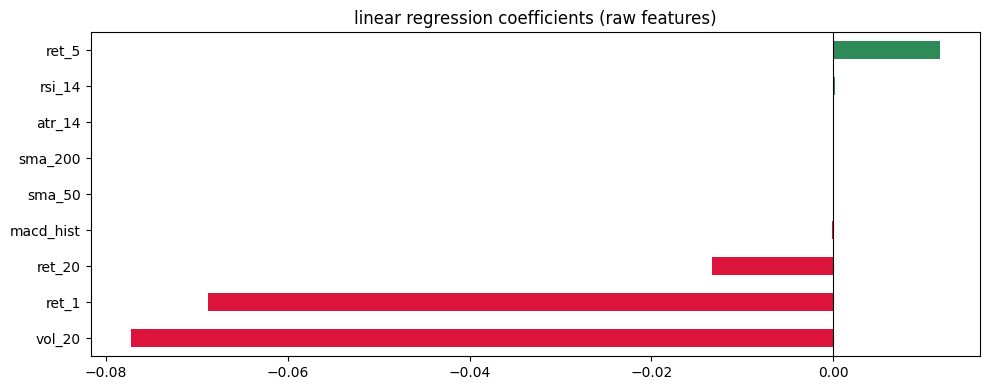

vol_20      -7.723856e-02
ret_1       -6.875905e-02
ret_20      -1.337753e-02
macd_hist   -7.885397e-05
sma_50      -4.685208e-06
sma_200      5.332171e-07
atr_14       1.984832e-05
rsi_14       2.220207e-04
ret_5        1.171321e-02
dtype: float64

In [16]:
coef = pd.Series(lin.coef_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["crimson" if v < 0 else "seagreen" for v in coef.values]
coef.plot.barh(ax=ax, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("linear regression coefficients (raw features)")
plt.tight_layout()
plt.show()

coef

## 6. Standardised coefficients

Fit again on **scaled** features (mean 0, std 1). Now coefficients
are directly comparable — bigger absolute value = more influential.

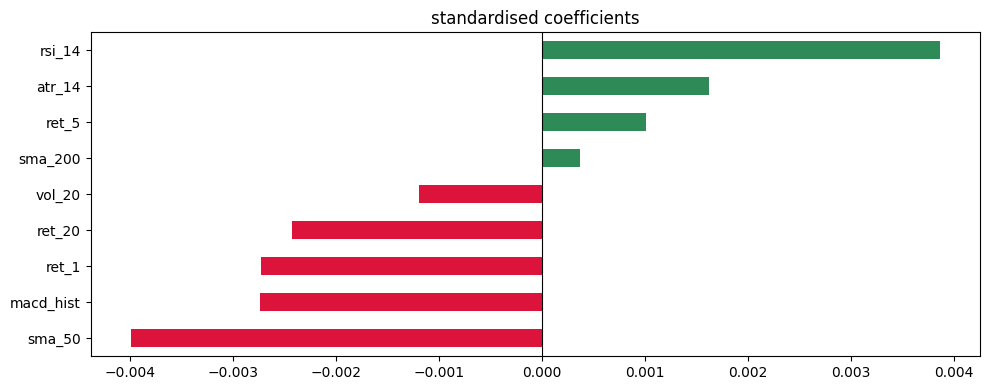

RMSE (scaled): 0.032851   dir: 52.40%

sma_50      -0.003990
macd_hist   -0.002739
ret_1       -0.002731
ret_20      -0.002429
vol_20      -0.001198
sma_200      0.000371
ret_5        0.001014
atr_14       0.001626
rsi_14       0.003862
dtype: float64


In [17]:
scaler = StandardScaler().fit(X_tr)
Xs_tr = scaler.transform(X_tr)
Xs_te = scaler.transform(X_te)

lin_std = LinearRegression().fit(Xs_tr, y_tr)
pred_std = lin_std.predict(Xs_te)

rmse_std = float(np.sqrt(mean_squared_error(y_te, pred_std)))
dir_std  = float(((pred_std > 0) == (y_te > 0)).mean())

coef_std = pd.Series(lin_std.coef_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["crimson" if v < 0 else "seagreen" for v in coef_std.values]
coef_std.plot.barh(ax=ax, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("standardised coefficients")
plt.tight_layout()
plt.show()

print(f"RMSE (scaled): {rmse_std:.6f}   dir: {dir_std:.2%}")
print()
print(coef_std)

## 7. Ridge regularisation sweep

Ridge adds L2 penalty `alpha * ||w||^2`. Higher alpha = stronger
shrinkage = more conservative. Sweep alphas, pick the best by test RMSE.

**Warning**: picking alpha by test RMSE is technically peeking.
A stricter setup would use walk-forward (see `05_walkforward.ipynb`).

In [18]:
alphas = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
rows = []
for a in alphas:
    m = Ridge(alpha=a).fit(Xs_tr, y_tr)
    p = m.predict(Xs_te)
    rows.append({
        "alpha":         a,
        "rmse":          float(np.sqrt(mean_squared_error(y_te, p))),
        "mae":           float(mean_absolute_error(y_te, p)),
        "dir_accuracy":  float(((p > 0) == (y_te > 0)).mean()),
    })
sweep = pd.DataFrame(rows)
sweep

,alpha,rmse,mae,dir_accuracy
0,0.01,0.032851,0.021927,0.524
1,0.10,0.032851,0.021927,0.524
2,1.00,0.032850,0.021927,0.524
3,10.00,0.032843,0.021924,0.528
4,100.00,0.032810,0.021905,0.520
5,1000.00,0.032806,0.021884,0.540


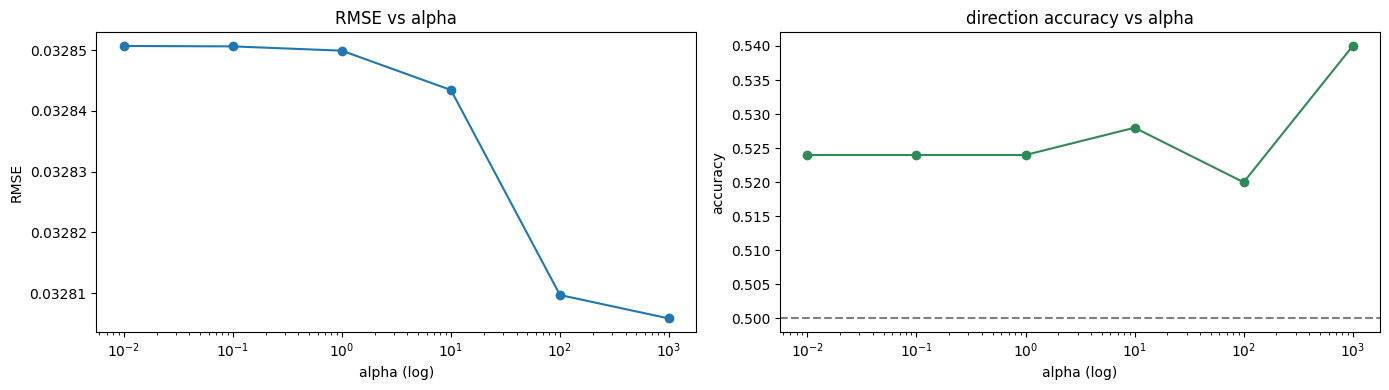

best alpha : 1000.0
  RMSE     : 0.032806
  dir acc  : 54.00%


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(sweep.alpha, sweep.rmse, marker="o")
ax[0].set_xscale("log")
ax[0].set_title("RMSE vs alpha")
ax[0].set_xlabel("alpha (log)")
ax[0].set_ylabel("RMSE")

ax[1].plot(sweep.alpha, sweep.dir_accuracy, marker="o", color="seagreen")
ax[1].axhline(0.5, ls="--", color="gray")
ax[1].set_xscale("log")
ax[1].set_title("direction accuracy vs alpha")
ax[1].set_xlabel("alpha (log)")
ax[1].set_ylabel("accuracy")

plt.tight_layout()
plt.show()

best = sweep.loc[sweep.rmse.idxmin()]
print(f"best alpha : {best.alpha}")
print(f"  RMSE     : {best.rmse:.6f}")
print(f"  dir acc  : {best.dir_accuracy:.2%}")

## 8. Predictions vs actual

Two panels:

- top: predicted next-day return vs actual
- bottom: cumulative return of a strategy that goes long when the
  model predicts > 0, short when < 0, flat otherwise (very naive)

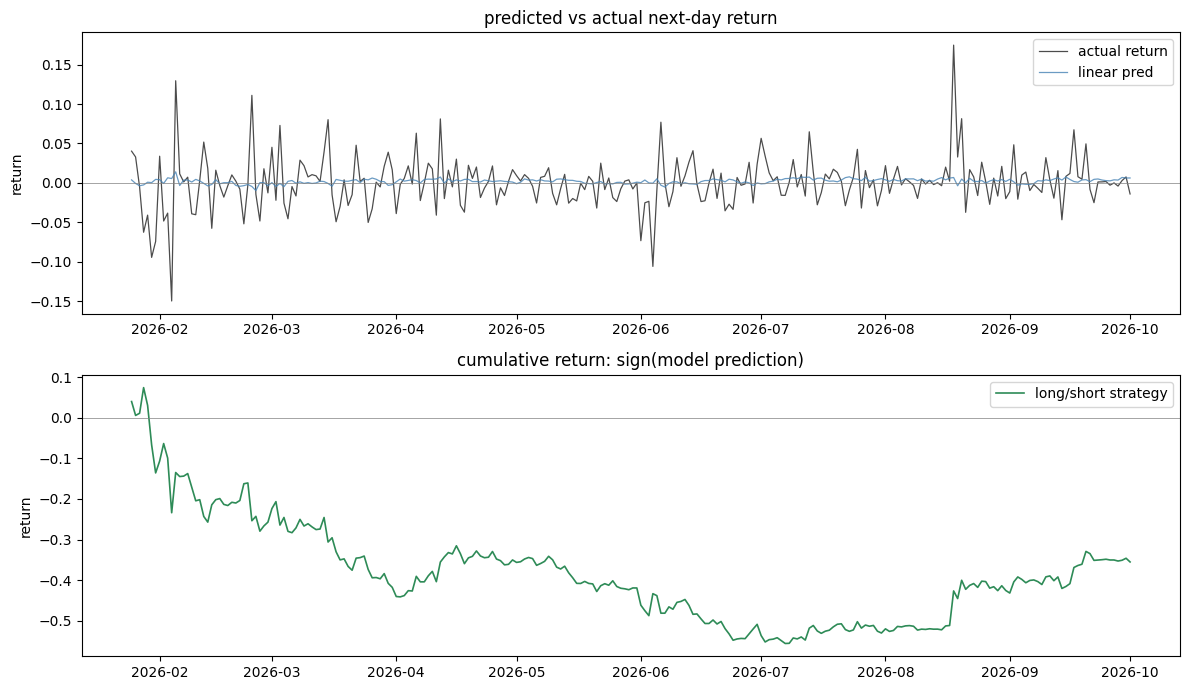

AttributeError: 'numpy.ndarray' object has no attribute 'iloc'

In [20]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=ax[0] if False else None)

# prediction vs actual
ax[0].plot(test.index, y_te, label="actual return", color="black", lw=0.9, alpha=0.7)
ax[0].plot(test.index, pred_lin, label="linear pred", color="steelblue", lw=0.9, alpha=0.8)
ax[0].axhline(0, color="gray", lw=0.5)
ax[0].set_title("predicted vs actual next-day return")
ax[0].set_ylabel("return")
ax[0].legend()

# naive long/short backtest
position = np.sign(pred_lin)      # +1 long, -1 short, 0 flat
pnl = position * y_te             # daily PnL of strategy
cum_pnl = (1 + pnl).cumprod() - 1

ax[1].plot(test.index, cum_pnl, label="long/short strategy", color="seagreen", lw=1.2)
ax[1].axhline(0, color="gray", lw=0.5)
ax[1].set_title("cumulative return: sign(model prediction)")
ax[1].set_ylabel("return")
ax[1].legend()

plt.tight_layout()
plt.show()

print(f"strategy total return: {cum_pnl.iloc[-1]:+.2%}")
print(f"strategy sharpe      : {pnl.mean() / pnl.std() * np.sqrt(365):.2f}")

## 9. Save results

Writes `reports/predictions/linear.json` for the comparison notebook.

In [ ]:
results = {
    "model": "linear_regression",
    "features": FEATURES,
    "test_days": int(len(test)),
    "test_start": str(test.index.min().date()),
    "test_end":   str(test.index.max().date()),
    "rmse":          rmse,
    "mae":           mae,
    "dir_accuracy":  dir_acc,
    "rmse_scaled":   rmse_std,
    "dir_scaled":    dir_std,
    "best_alpha":    float(best.alpha),
    "coefficients":  {k: float(v) for k, v in coef_std.items()},
}

path = PRED_DIR / "linear.json"
path.write_text(json.dumps(results, indent=2), encoding="utf-8")
print(f"wrote {path}")

## Next steps

- **03_tree_models.ipynb** — do non-linear interactions help?
- **05_walkforward.ipynb** — honest evaluation (this is where
  most models collapse)
- **06_feature_importance.ipynb** — which features actually drive
  predictions

**Verdict rule of thumb**:

| Test RMSE vs baseline | Test dir acc | Verdict |
|---|---|---|
| > 5% better | > 53% | worth pursuing |
| 2–5% better | 51–53% | marginal, needs more features |
| < 2% better | ≤ 51% | no edge — stop |